# Learned Dynamics

> **About this notebook, version 1.0.0 (17 November 2026).** The last of five notebooks of *Polymer Neural Nets*. Equation numbers such as (9.1) refer to the theory notebook 00, and the reference values come from notebook 02. The full checks were run with `scripts/run_md.py` and are stored in `results/`; this notebook shows them and repeats a short run live. Python 3.14 with NumPy, SciPy, Matplotlib, PyTorch, PyTorch Geometric and OpenMM.

*The trained networks drive the simulation: OpenMM moves the beads with forces from the network, and the chains must conserve energy, keep their bonds and angles, and swell as real self-avoiding chains do*

**Dara O Shayda**  
Republic of Ireland  
*dara@compclassnotes.com*  

**Noor Hoshino**  
<img alt="نور 星野" src="figures/noor-name.png" height="22">  
Advanced AI System Programming  
Hokkaido Prefecture, Japan  
*noor@compclassnotes.com*  
Computational Classnotes · revision 1  

<p align='left' style='color:#666666'><i>© Computational Classnotes · CC BY-NC-SA 4.0</i></p>

## Abstract

A force field is useful only if a simulation driven by it behaves like the real system. This notebook replaces OpenMM's exact Kremer–Grest forces with the forces of the two trained graph networks, and runs the three checks of notebook 02 on the result. Section 1 shows how a network is plugged into OpenMM through a custom external force whose per-bead parameters are refreshed every step, and runs it live. Section 2 checks energy conservation. With the learned forces the total energy fluctuates exactly as much as with the exact forces, and does not drift, at three time steps: the learned energy surface is smooth and conservative, as Theorems 6 and 8 of notebook 00 promise. Section 3 checks the local structure: bond-length and bond-angle distributions from OpenMM driven by the networks agree with the reference. Section 4 checks the global structure. Chains of 16, 32 and 64 beads, two of these lengths never seen in training, reach the same size as the reference chains, and so the same effective exponent ν. Section 5 measures the cost, and section 6 lists the limits of these results and the next steps.

**Keywords:** learned force field; OpenMM; CustomExternalForce; velocity Verlet; BAOAB; energy conservation; bond-length distribution; Wasserstein distance; radius of gyration; Flory exponent; transferability; computational cost

## Index

- Section 1, the network inside OpenMM: Eq. (1), Table 1, cell c.1.
- Section 2, energy conservation: Figure 1, Table 2, cell c.2.
- Section 3, bonds and angles: Eq. (2), Figure 2, Table 3, cell c.3.
- Section 4, the size of the chain: Figure 3, Table 4, cell c.4.
- Section 5, cost: Table 5, cell c.5.
- Section 6, limits and next steps.

## 0. Settings

Cell c.0 makes the notebook run in any Jupyter: it installs missing libraries, finds the repository folder or downloads it once from GitHub into `~/polymer-neural-nets` when this notebook is opened on its own, and sets the style of figures and tables.

In [1]:
# c.0
# Setup. This cell makes the notebook run in any Jupyter, three ways:
#  (1) inside the repository folder (e.g. `uv run jupyter lab`, or `pip install -r requirements.txt` then `jupyter lab`);
#  (2) in any Python environment: libraries that are missing are installed with pip into this kernel;
#  (3) as a single notebook file on its own: the code and data of the repository are downloaded once from
#      GitHub into the folder polymer-neural-nets in your home folder.
import importlib.util, subprocess, sys, io, zipfile, urllib.request, warnings
from pathlib import Path
warnings.filterwarnings("ignore")   # library notices (tqdm, TorchScript) are not part of the results
NEED = {"numpy": "numpy", "scipy": "scipy", "sympy": "sympy", "matplotlib": "matplotlib", "torch": "torch",
        "torch_geometric": "torch-geometric", "openmm": "openmm", "IPython": "ipython"}
missing = [pkg for mod, pkg in NEED.items() if importlib.util.find_spec(mod) is None]
if sys.platform == "emscripten":                                 # JupyterLite / Pyodide: Python inside the web page
    raise SystemExit("\n".join([
        "This Jupyter runs Python inside the web browser (JupyterLite / Pyodide, WebAssembly).",
        "PyTorch and OpenMM are not available there, and nothing can be installed with pip, so this notebook",
        "cannot run in it. The saved results are still shown in the notebook, and in the .md and .pdf editions.",
        "",
        "To run it, use Jupyter with a real Python on your computer. It also opens in the browser. In a terminal:",
        "  1. install uv (once):   curl -LsSf https://astral.sh/uv/install.sh | sh",
        "                          (Windows PowerShell: irm https://astral.sh/uv/install.ps1 | iex)",
        "  2. get the repository:  git clone https://github.com/lossofgenerality/polymer-neural-nets",
        "                          cd polymer-neural-nets",
        "  3. install and start:   uv sync   then   uv run jupyter notebook",
        "Then open this notebook in the Jupyter tab that appears and choose Kernel → Restart Kernel and Run All Cells."]))
def install(pkgs):
    """Install pkgs into the Python of this kernel; try pip, then uv; explain clearly if neither works."""
    import shutil
    tries = [[sys.executable, "-m", "pip", "install", *pkgs]]
    if shutil.which("uv"):
        tries.append(["uv", "pip", "install", "--python", sys.executable, *pkgs])
    errors = []
    for cmd in tries:
        try:
            r = subprocess.run(cmd, capture_output=True, text=True)
            if r.returncode == 0:
                importlib.invalidate_caches(); return
            errors.append(f"{' '.join(cmd[:4])} …: exit code {r.returncode}\n{(r.stderr or r.stdout)[-1200:]}")
        except OSError as e:
            errors.append(f"{' '.join(cmd[:4])} …: could not be started ({e})")
    managed = any("externally-managed" in e for e in errors)
    raise SystemExit("\n".join([
        "Could not install " + ", ".join(pkgs) + " into the Python of this Jupyter kernel:", "    " + sys.executable, "",
        *errors, "",
        "Fix it in a terminal, in the folder of this repository, with one of these, then restart the kernel:",
        "  (a) uv:   uv sync   and then   uv run jupyter notebook      (uses the exact versions of uv.lock)",
        "  (b) venv: python3 -m venv .venv && source .venv/bin/activate && pip install -r requirements.txt && jupyter notebook",
        "            (Windows: .venv\\Scripts\\activate)",
        f"  (c) this kernel's Python: \"{sys.executable}\" -m pip install " + " ".join(pkgs),
        "This Python is managed by the system or Homebrew and refuses installs: use (a) or (b)." if managed else ""]))
if missing:
    print("installing", ", ".join(missing), "(first run only; torch is large) ...")
    install(missing)
def find_repo():
    for q in [Path.cwd(), *Path.cwd().parents]:                  # (1) this notebook is inside the repository
        if (q / "src" / "polymer_nn").is_dir() and (q / "data").is_dir():
            return q
    home = Path.home() / "polymer-neural-nets"                    # (3) download it once
    if not (home / "src" / "polymer_nn").is_dir():
        url = "https://github.com/lossofgenerality/polymer-neural-nets/archive/refs/heads/main.zip"
        print("downloading the repository (code, data, models) from", url)
        with zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read())) as z:
            top = z.namelist()[0].split("/")[0]
            for m in z.infolist():
                rel = m.filename[len(top) + 1:]
                if rel and not m.is_dir():
                    (home / rel).parent.mkdir(parents=True, exist_ok=True)
                    (home / rel).write_bytes(z.read(m))
    return home
ROOT = find_repo()
sys.path.insert(0, str(ROOT / "src"))                             # use the repository's polymer_nn
import json, math, time
import numpy as np
import matplotlib.pyplot as plt
import torch
from polymer_nn import nbtools as nb
from polymer_nn.nbtools import table, nform, sci, savefig, figFont, wFull, wHalf, red, blue, green, orange, grey
nb.setup(threads=2)                 # plot style and 2 CPU threads; figures are saved in ./figures
DATA = ROOT / "data"                # the reference data made by scripts/generate_data.py
torch.manual_seed(0); rng = np.random.default_rng(0)
print("repository folder:", ROOT.name, "| Python", sys.version.split()[0], "| torch", torch.__version__, "| numpy", np.__version__)

repository folder: polymer-neural-nets | Python 3.14.6 | torch 2.15.0+cu132 | numpy 2.5.5


## 1. The network inside OpenMM

OpenMM accepts custom forces defined by an energy formula. A `CustomExternalForce` with energy

$$
U_{\text{ext}}(x) = -\sum_i \bigl( f_{x,i}\, x_i + f_{y,i}\, y_i + f_{z,i}\, z_i \bigr) , \qquad -\frac{\partial U_{\text{ext}}}{\partial x_i} = (f_{x,i}, f_{y,i}, f_{z,i}) \tag{1}
$$

exerts on bead i exactly the force (f_x, f_y, f_z)_i. These are per-bead parameters that can be changed between steps. `polymer_nn.md.OpenMMLearnedSimulation` uses this. Before every step it reads the positions, builds the graph, evaluates the network (energy and forces), writes the forces into the parameters with `updateParametersInContext`, and lets OpenMM's integrator take one step. OpenMM's thermostats, integrators and reporters are then used unchanged with the learned forces. Cell c.1 runs a 32-bead chain this way at k_BT = 1, starting from a training frame.

In [2]:
# c.1
# a live OpenMM run driven by the trained InvariantGNN
from polymer_nn.models import load_model
from polymer_nn.md import LearnedPotential, OpenMMLearnedSimulation
from polymer_nn import analysis as A
d32 = np.load(DATA / "kg_N32.npz")
inv, ck = load_model(ROOT / "models/invariant.pt")
t0 = time.time()
sim = OpenMMLearnedSimulation(LearnedPotential(inv, 32, ck["energy_offset"]), d32["positions"][-1], integrator="langevin", seed=5)
out = sim.run(40, stride=25)
table([["quantity", "value", "expected"], ["steps run", "1000 (5 τ)", ""], ["wall time", f"{time.time() - t0:.1f} s", ""],
       ["mean bond length (σ)", f"{A.bond_lengths(out['positions']).mean():.4f}", "0.971 (notebook 02)"],
       ["mean kinetic energy per bead (ε)", f"{out['kinetic'].mean() / 32:.3f}", "1.5 = (3/2) k_BT"],
       ["learned potential energy per bead (ε)", f"{out['potential'].mean() / 32:.3f}", "≈ 20 (reference, notebook 01)"]], "Table 1. OpenMM with the network's forces, live")

quantity,value,expected
steps run,1000 (5 τ),
wall time,3.1 s,
mean bond length (σ),0.9718,0.971 (notebook 02)
mean kinetic energy per bead (ε),1.457,1.5 = (3/2) k_BT
learned potential energy per bead (ε),20.168,"≈ 20 (reference, notebook 01)"


## 2. Energy conservation

Without a thermostat the total energy H = K + Ê must be conserved (notebook 00, Theorem 8). Here Ê is the *learned* energy, and the forces are its exact gradient. Any drift would mean that the forces are not the gradient of a smooth function, for example because an edge switched on with a jump. `scripts/run_md.py` ran velocity Verlet (Eq. (9.1)) for 4 τ from the same starting frame and velocities with the learned forces and with the exact OpenMM forces, at Δt = 0.004, 0.002 and 0.001 τ. Cell c.2 shows the results.

Δt (τ),forces,drift of H per bead per τ,std of H per bead
0.004,exact (OpenMM),6.8 × 10⁻⁶,8.5 × 10⁻⁴
,invariant,1.8 × 10⁻⁵,8 × 10⁻⁴
,egnn,4.5 × 10⁻⁵,8.9 × 10⁻⁴
0.002,exact (OpenMM),-2.1 × 10⁻⁶,2.2 × 10⁻⁴
,invariant,-2.3 × 10⁻⁶,2 × 10⁻⁴
,egnn,8.9 × 10⁻⁶,2.2 × 10⁻⁴
0.001,exact (OpenMM),-1.3 × 10⁻⁶,5.5 × 10⁻⁵
,invariant,5.2 × 10⁻⁸,5 × 10⁻⁵
,egnn,3.5 × 10⁻⁶,5.4 × 10⁻⁵


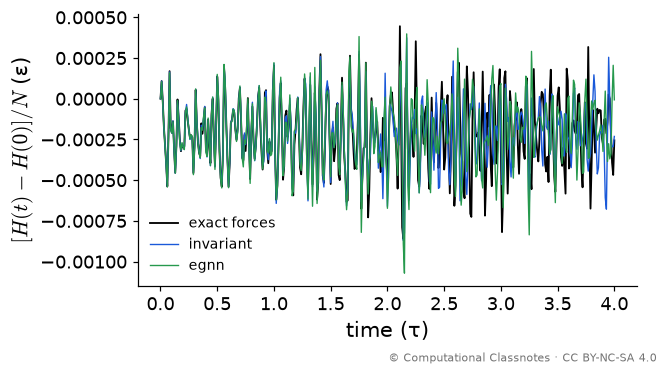

In [3]:
# c.2
# NVE energy conservation: learned against exact forces (results of scripts/run_md.py)
R = {n: json.loads((ROOT / f"results/checks_{n}.json").read_text()) for n in ("invariant", "egnn")}
Z = {n: np.load(ROOT / f"results/checks_{n}.npz") for n in R}
rows = [["Δt (τ)", "forces", "drift of H per bead per τ", "std of H per bead"]]
for dt in ("0.004", "0.002", "0.001"):
    rows.append([dt, "exact (OpenMM)", sci(R["invariant"]["nve"][dt]["reference"]["drift_per_bead_per_tau"]), sci(R["invariant"]["nve"][dt]["reference"]["std_per_bead"])])
    for n in R:
        rows.append(["", n, sci(R[n]["nve"][dt]["learned"]["drift_per_bead_per_tau"]), sci(R[n]["nve"][dt]["learned"]["std_per_bead"])])
table(rows, "Table 2. Energy conservation in NVE, 32 beads, 4 τ")
fig, ax = plt.subplots(figsize=(wFull, wHalf * 1.15)); z0 = Z["invariant"]
ax.plot(z0["nve_time"], (z0["nve_ref_total"] - z0["nve_ref_total"][0]) / 32, color="k", lw=1.2, label="exact forces")
for n, c in (("invariant", blue), ("egnn", green)):
    ax.plot(Z[n]["nve_time"], (Z[n]["nve_learned_total"] - Z[n]["nve_learned_total"][0]) / 32, color=c, lw=0.9, label=n)
ax.set(xlabel="time (τ)", ylabel=r"$[H(t) - H(0)]/N$ (ε)"); ax.legend(fontsize=9); fig.tight_layout(); savefig(fig, "fig1_nve"); plt.show()

*Figure 1. Total energy per bead during constant-energy runs at Δt = 0.002 τ, with the exact forces (black) and with the forces of the two networks. The three curves fluctuate by the same amount, and none drifts.*

The fluctuations with learned forces have the same size as with exact forces and shrink by about 4 when Δt is halved. The drift is of the order of 10⁻⁶–10⁻⁵ ε per bead per τ, as small as with the exact forces. The learned energy surfaces are therefore smooth enough for velocity Verlet: the cosine envelope removes the jumps at the cutoff (notebook 00, Theorem 6), and the forces are exact gradients (Theorem 8).

## 3. Bonds and angles

`scripts/run_md.py` also ran OpenMM's Langevin integrator (k_BT = 1, γ = 1/τ, Δt = 0.005 τ) with the learned forces. After 2000 steps of equilibration it recorded 200 frames 50 steps apart, and it compared the bond lengths and bond angles with the reference data. The distance between two distributions is measured by the Wasserstein-1 distance,

$$
W_1 = \int \bigl| C_{\text{learned}}(t) - C_{\text{ref}}(t) \bigr| \, dt , \tag{2}
$$

where C is the cumulative distribution. W₁ is the average distance by which probability must be moved to turn one distribution into the other, in the unit of the variable (σ for bonds, radians for angles).

model,mean bond shift (σ),W₁ bonds (σ),KS bonds,W₁ angles (°),KS angles,⟨K⟩ per bead (ε)
invariant,-0.0004,0.0005,0.009,0.87,0.018,1.544
egnn,-0.0005,0.0005,0.010,0.34,0.010,1.476
for scale: reference widths,,bond std 0.034,,angle std 28.0°,,1.5 expected


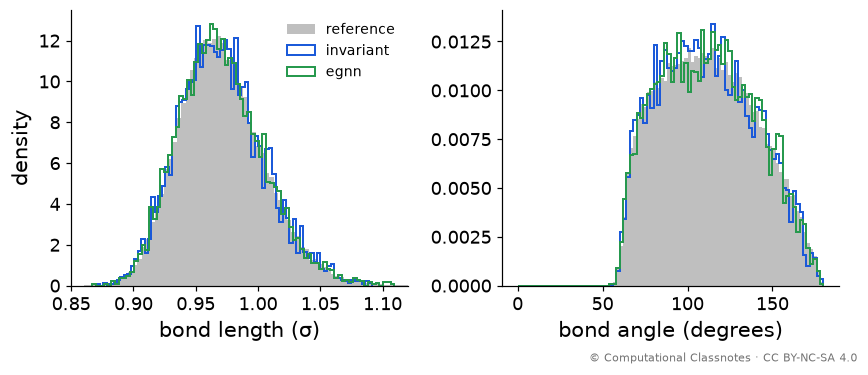

In [4]:
# c.3
# bond-length and bond-angle distributions with the learned forces
rows = [["model", "mean bond shift (σ)", "W₁ bonds (σ)", "KS bonds", "W₁ angles (°)", "KS angles", "⟨K⟩ per bead (ε)"]]
for n in R:
    s = R[n]["structure"]
    rows.append([n, f"{s['bond_length']['mean_diff']:+.4f}", f"{s['bond_length']['wasserstein']:.4f}", f"{s['bond_length']['ks_stat']:.3f}",
                 f"{np.degrees(s['bond_angle']['wasserstein']):.2f}", f"{s['bond_angle']['ks_stat']:.3f}", f"{s['kinetic_per_bead_over_kT']:.3f}"])
table(rows + [["for scale: reference widths", "", f"bond std {Z['invariant']['ref_bond'].std():.3f}", "", f"angle std {np.degrees(Z['invariant']['ref_angle']).std():.1f}°", "", "1.5 expected"]], "Table 3. Local structure with the learned forces")
fig, ax = plt.subplots(1, 2, figsize=(wFull * 1.3, wHalf * 1.15))
ax[0].hist(Z["invariant"]["ref_bond"], bins=80, density=True, color="0.75", label="reference")
ax[1].hist(np.degrees(Z["invariant"]["ref_angle"]), bins=90, range=(0, 180), density=True, color="0.75", label="reference")
for n, c in (("invariant", blue), ("egnn", green)):
    ax[0].hist(Z[n]["omm_bond"], bins=80, density=True, histtype="step", color=c, lw=1.3, label=n)
    ax[1].hist(np.degrees(Z[n]["omm_angle"]), bins=90, range=(0, 180), density=True, histtype="step", color=c, lw=1.3, label=n)
ax[0].set(xlabel="bond length (σ)", ylabel="density", xlim=(0.85, 1.12)); ax[1].set(xlabel="bond angle (degrees)")
ax[0].legend(fontsize=9); fig.tight_layout(); savefig(fig, "fig2_bonds_angles"); plt.show()

*Figure 2. Bond lengths (left) and bond angles (right) from OpenMM driven by each network (lines), against the reference simulation (grey). The learned histograms are noisier only because they hold 200 frames instead of 2000.*

The mean bond length is off by less than 10⁻³ σ, and both distributions are within a small fraction of their width of the reference. The KS statistics of order 0.01–0.02 mean that the largest gap between the cumulative distributions is 1–2%. The mean kinetic energy per bead is within a few per cent of 1.5 ε. OpenMM reports it at half steps, and 200 frames of a single chain fluctuate by about that much.

## 4. The size of the chain: R_g on unseen lengths

The most demanding check is the global shape. A small systematic error in the forces between beads far apart along the chain would make the chain too compact or too swollen, and this shows up only in long runs. `scripts/run_md.py` ran BAOAB Langevin dynamics (notebook 00, Eq. (9.4); `polymer_nn.md.langevin_batched`) with γ = 0.1/τ, 8 independent chains at a time, for 20 000 steps (100 τ), at N = 16, 32 and 64. It discarded the first quarter of each run as equilibration. The starting walks were relaxed by pivot Monte Carlo with excluded volume but generic bonds of 0.97 σ, so the network had to set the bonds and the local structure itself. Chains of 16 and 64 beads were never seen in training.

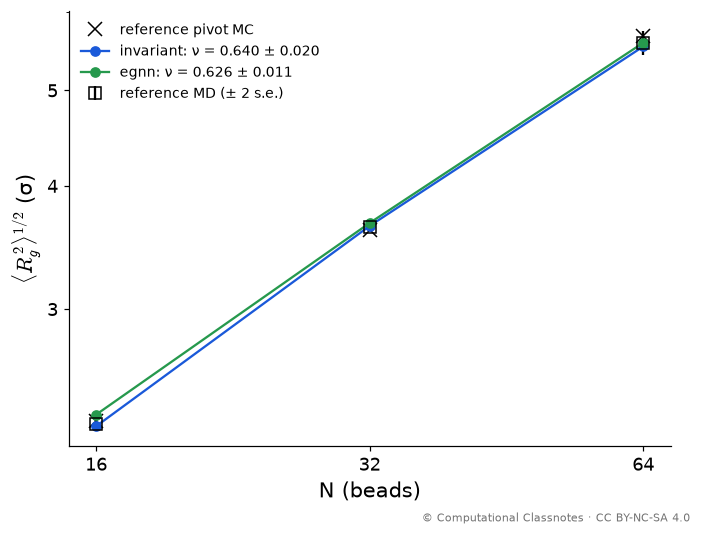

N,reference MD,pivot MC,invariant,egnn,in training?
16,2.292 ± 0.004,2.312,2.282,2.344,no
32,3.637 ± 0.018,3.604,3.643,3.668,yes
64,5.587 ± 0.079,5.679,5.538,5.586,no
ν (fit),0.643 ± 0.014,0.648,0.640 ± 0.020,0.626 ± 0.011,


In [5]:
# c.4
# R_g at N = 16, 32, 64 with the learned forces, against MD and pivot-MC references
S = np.load(DATA / "scaling_kg.npz"); keep = [i for i, N in enumerate(S["sizes"]) if N <= 64]
Ns = S["sizes"][keep]; ref_md = S["kg_rg"][keep]; ref_pv = S["kg_pivot_rg"][keep]; sem = S["kg_rg_sem"][keep]
fig, ax = plt.subplots(figsize=(wFull * 1.05, wFull * 0.8))
ax.errorbar(Ns, ref_md, yerr=2 * sem, fmt="s", color="k", mfc="none", ms=8, label="reference MD (± 2 s.e.)")
ax.plot(Ns, ref_pv, "x", color="k", ms=9, label="reference pivot MC")
rows = [["N", "reference MD", "pivot MC"] + [n for n in R] + ["in training?"]]
for n, c in (("invariant", blue), ("egnn", green)):
    sc = R[n]["scaling"]; ax.plot(sc["sizes"], sc["rg"], "o-", color=c, label=f"{n}: ν = {sc['nu']:.3f} ± {sc['nu_err']:.3f}")
for k, N in enumerate(Ns):
    rows.append([int(N), f"{ref_md[k]:.3f} ± {sem[k]:.3f}", f"{ref_pv[k]:.3f}"] + [f"{R[n]['scaling']['rg'][k]:.3f}" for n in R] + ["yes" if N == 32 else "no"])
fref = A.fit_flory_exponent(Ns, ref_md)
rows.append(["ν (fit)", f"{fref.nu:.3f} ± {fref.nu_err:.3f}", f"{A.fit_flory_exponent(Ns, ref_pv).nu:.3f}"] + [f"{R[n]['scaling']['nu']:.3f} ± {R[n]['scaling']['nu_err']:.3f}" for n in R] + [""])
ax.set(xscale="log", yscale="log", xlabel="N (beads)", ylabel=r"$\langle R_g^2\rangle^{1/2}$ (σ)"); nb.logticks(ax, [16, 32, 64], [2, 3, 4, 5])
ax.legend(fontsize=9); fig.tight_layout(); savefig(fig, "fig3_scaling"); plt.show()
table(rows, "Table 4. ⟨R_g²⟩^½ (σ) with learned and exact forces")

*Figure 3. The size of chains simulated with the learned forces (circles) against the reference simulations with the exact forces (squares: MD; crosses: pivot Monte Carlo). Both networks were trained on 32-bead chains only. The 16- and 64-bead chains are a test of transferability.*

The learned chains have the right size at every length, within 1–3% of the references, which is about as large as the difference between the two reference methods themselves. So they have the right effective exponent too. Two things make this possible: the energy is a sum of local terms, and the networks were trained on configurations from the right distribution, which contain many non-bonded contacts.

## 5. Cost

Cell c.5 times one force evaluation for a 64-bead chain on this CPU: the exact force field in OpenMM, and each network called from Python.

In [6]:
# c.5
# time per force evaluation, 64 beads, one CPU thread
from polymer_nn.md import reference_potential
torch.set_num_threads(1)
x64 = np.load(DATA / "kg_N64.npz")["positions"][0].astype(float)
egnn, ck_e = load_model(ROOT / "models/egnn.pt")
rows = [["force field", "time per evaluation", "relative"]]
pots = [("exact Kremer–Grest (OpenMM, Reference platform)", reference_potential(64)), ("InvariantGNN", LearnedPotential(inv, 64)), ("EquivariantGNN", LearnedPotential(egnn, 64))]
times = []
for name, pot in pots:
    pot(x64); t0 = time.perf_counter(); n_rep = 50
    for _ in range(n_rep): pot(x64)
    times.append((time.perf_counter() - t0) / n_rep)
for (name, _), t in zip(pots, times): rows.append([name, f"{t * 1e3:.2f} ms", f"{t / times[0]:.0f} ×"])
table(rows, "Table 5. Cost of one force evaluation (64 beads)")
torch.set_num_threads(2)

force field,time per evaluation,relative
"exact Kremer–Grest (OpenMM, Reference platform)",0.26 ms,1 ×
InvariantGNN,3.48 ms,13 ×
EquivariantGNN,5.94 ms,23 ×


For the Kremer–Grest model itself the networks are 10–20 times slower than the exact formula, which takes a few arithmetic operations per pair. That is expected and not the point. The purpose of this repository is to build and validate the method on a model where the exact answer is known. The method pays off when the reference is expensive: all-atom force fields, quantum-chemical energies, or coarse-grained potentials of mean force that have no simple formula (notebook 00, section 8). There the network costs the same as here, a few thousand operations per bead, and the reference costs far more. On a GPU, and through `openmm-torch` instead of a Python call every step, the cost per bead drops by orders of magnitude (`docs/running-large.md`).

## 6. Limits and next steps

- **Long chains.** At N = 128 the reference MD and pivot MC differ by about 5%, because MD of 128-bead chains needs many more Rouse times than were run. Scaling studies at large N should use pivot MC for the reference, or much longer MD, and the learned model should be tested at those lengths.
- **The energy constant.** Trained at one chain length, the absolute energy on other lengths carries a constant shift per bead (notebook 03, section 6). Training on two lengths fixes it; forces and dynamics do not depend on it.
- **Melts and solutions.** All data here are single chains in implicit solvent. Melts need periodic boxes and neighbour lists (cell lists) for 10⁴–10⁶ beads (`docs/running-large.md`).
- **Higher-order equivariant models.** NequIP and MACE [batzner2022, batatia2022] can replace `EquivariantGNN` with no other change, since anything with the interface of `polymer_nn.models._EnergyModel` works with the training and MD code.
- **Coarse-graining, generative models, property prediction.** These are the next stages of the project brief; the mapping utilities are in `polymer_nn.coarse_grain`.

## References

- [eastman2024] P. Eastman et al., OpenMM 8: Molecular dynamics simulation with machine learning potentials, J. Phys. Chem. B 128 (2024) 109–116. doi:10.1021/acs.jpcb.3c06662
- [leimkuhler2013] B. Leimkuhler, C. Matthews, Appl. Math. Res. Express 2013 (2013) 34–56. doi:10.1093/amrx/abs010
- [batzner2022] S. Batzner et al., Nat. Commun. 13 (2022) 2453. doi:10.1038/s41467-022-29939-5
- [batatia2022] I. Batatia et al., MACE, NeurIPS 35 (2022), arXiv:2206.07697.
- [wang2019] J. Wang et al., Machine learning of coarse-grained molecular dynamics force fields, ACS Cent. Sci. 5 (2019) 755–767. doi:10.1021/acscentsci.8b00913
- The complete bibliography: `docs/REFERENCES.md`.

<p align='center' style='color:#666666'><i>© Computational Classnotes · CC BY-NC-SA 4.0</i></p>